In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/cancer_stage_data.csv")

# Dataset dimensions
print("Dataset shape:", df.shape)

# First five rows
display(df.head())

# Column names and data types
df.info()

# Statistical summary
display(df.describe(include="all"))

# Missing values
print(df.isnull().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (32624, 17)


,ID,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,end_treatment_date,survived
0,0,56.0,Female,Slovenia,2015-07-28,Stage IV,No,Former Smoker,18.9,228.0,1.0,0.0,0.0,0.0,Combined,2016-02-17,0.0
1,1,58.0,Male,Luxembourg,2015-08-14,Stage III,Yes,Current Smoker,20.8,198.0,1.0,0.0,0.0,0.0,Radiation,2016-04-25,0.0
2,2,57.0,Female,Austria,2017-07-06,Stage III,Yes,Current Smoker,40.9,265.0,1.0,1.0,1.0,0.0,Radiation,2019-03-16,0.0
3,3,61.0,Female,Malta,2016-09-06,Stage IV,Yes,Current Smoker,20.4,178.0,0.0,0.0,1.0,0.0,Radiation,2017-05-22,1.0
4,4,54.0,Female,Sweden,2024-04-27,Stage II,No,Never Smoked,37.0,278.0,1.0,0.0,0.0,0.0,Chemotherapy,2026-03-28,1.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32624 entries, 0 to 32623
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  32624 non-null  int64  
 1   age                 32563 non-null  float64
 2   gender              32624 non-null  object 
 3   country             32624 non-null  object 
 4   diagnosis_date      32624 non-null  object 
 5   cancer_stage        32624 non-null  object 
 6   family_history      32624 non-null  object 
 7   smoking_status      32624 non-null  object 
 8   bmi                 32570 non-null  float64
 9   cholesterol_level   32548 non-null  float64
 10  hypertension        32570 non-null  float64
 11  asthma              32550 non-null  float64
 12  cirrhosis           32559 non-null  float64
 13  other_cancer        32577 non-null  float64
 14  treatment_type      32624 non-null  object 
 15  end_treatment_date  32624 non-null  object 
 16  surv

,ID,age,gender,country,diagnosis_date,cancer_stage,family_history,smoking_status,bmi,cholesterol_level,hypertension,asthma,cirrhosis,other_cancer,treatment_type,end_treatment_date,survived
count,32624.000000,3.256300e+04,32624,32624,32624,32624,32624,32624,3.257000e+04,3.254800e+04,32570.000000,32550.000000,32559.000000,32577.000000,32624,32624,32555.00000
unique,NaN,NaN,2,27,3648,4,2,4,NaN,NaN,NaN,NaN,NaN,NaN,4,4155,NaN
top,NaN,NaN,Male,Ireland,2015-01-09,Stage IV,No,Former Smoker,NaN,NaN,NaN,NaN,NaN,NaN,Combined,2016-05-27,NaN
freq,NaN,NaN,16479,1315,30,12985,16354,8328,NaN,NaN,NaN,NaN,NaN,NaN,8301,28,NaN
mean,16311.500000,5.123123e+02,NaN,NaN,NaN,NaN,NaN,NaN,3.907300e+02,9.190069e+03,16.111514,9.681475,0.210080,0.075912,NaN,NaN,6.34345
std,9417.881927,4.808908e+04,NaN,NaN,NaN,NaN,NaN,NaN,3.348597e+04,4.393908e+05,1238.928310,959.996892,0.407372,0.264862,NaN,NaN,783.78810
min,0.000000,3.060000e-06,NaN,NaN,NaN,NaN,NaN,NaN,1.398000e-06,1.446000e-05,0.000000,0.000000,0.000000,0.000000,NaN,NaN,0.00000
25%,8155.750000,4.800000e+01,NaN,NaN,NaN,NaN,NaN,NaN,2.360000e+01,1.990000e+02,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.00000
50%,16311.500000,5.500000e+01,NaN,NaN,NaN,NaN,NaN,NaN,3.060000e+01,2.420000e+02,1.000000,0.000000,0.000000,0.000000,NaN,NaN,0.00000
75%,24467.250000,6.100000e+01,NaN,NaN,NaN,NaN,NaN,NaN,3.760000e+01,2.700000e+02,1.000000,1.000000,0.000000,0.000000,NaN,NaN,0.00000


ID                     0
age                   61
gender                 0
country                0
diagnosis_date         0
cancer_stage           0
family_history         0
smoking_status         0
bmi                   54
cholesterol_level     76
hypertension          54
asthma                74
cirrhosis             65
other_cancer          47
treatment_type         0
end_treatment_date     0
survived              69
dtype: int64
Duplicate rows: 0


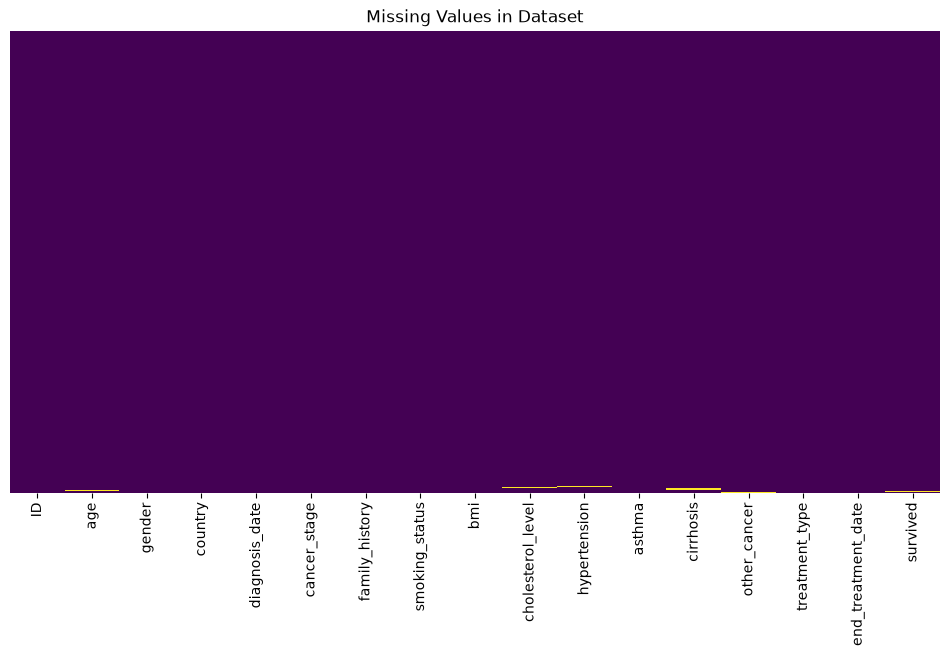

In [3]:
# Visualize missing values
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Dataset")
plt.show()

Numerical columns: ['ID', 'age', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer', 'survived']


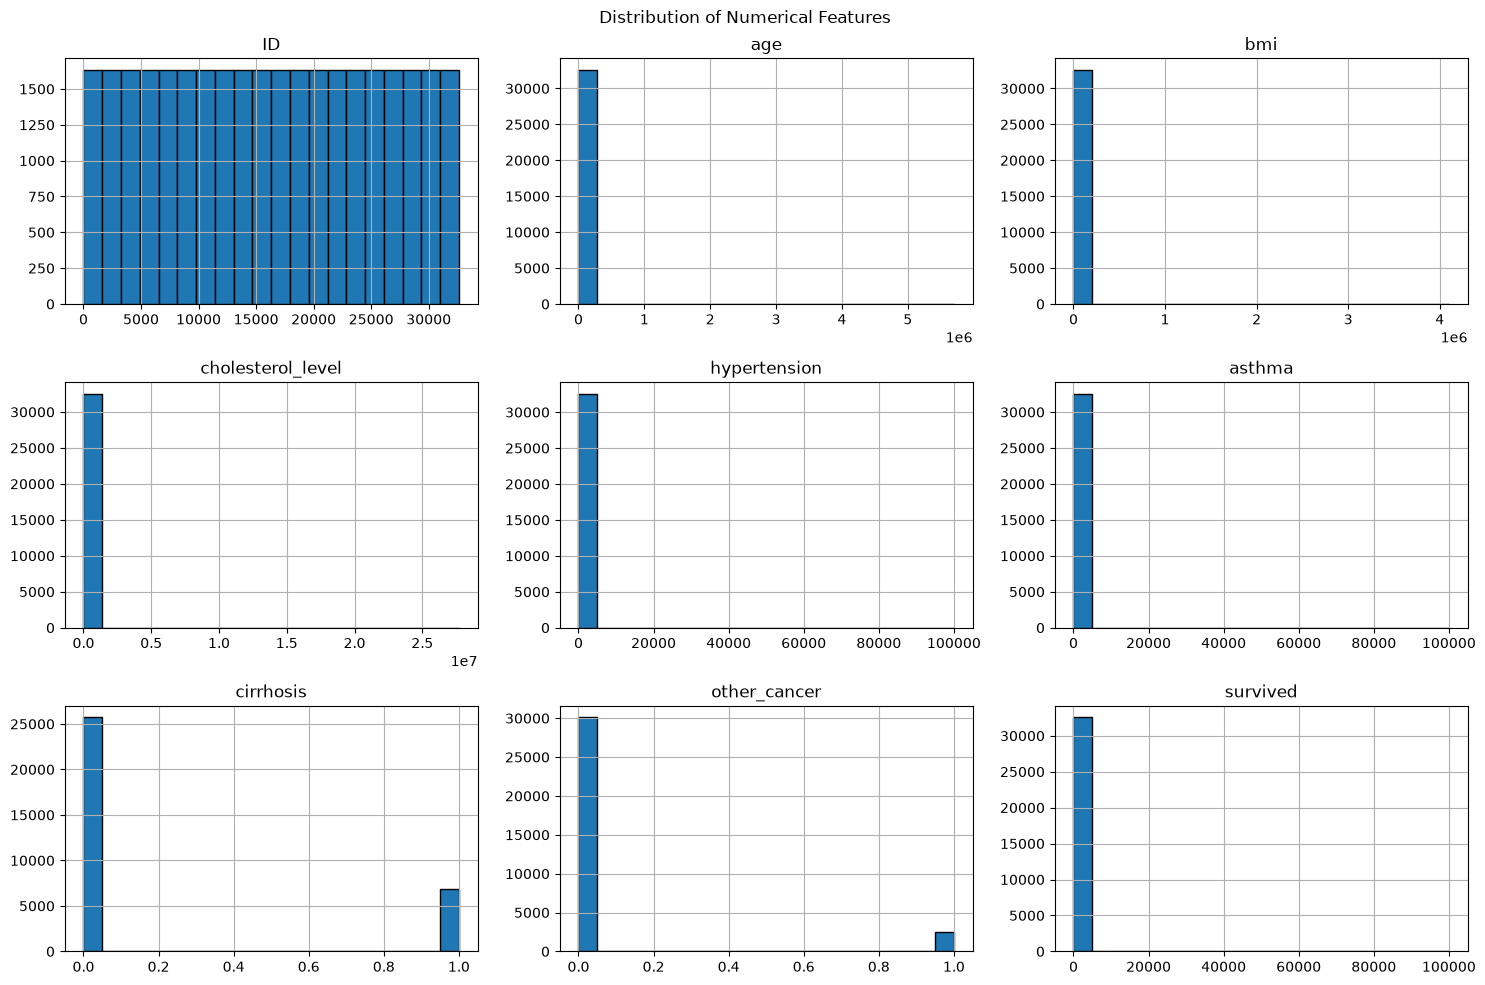

In [4]:
# Select numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

print("Numerical columns:", list(numerical_columns))

# Plot distributions
df[numerical_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

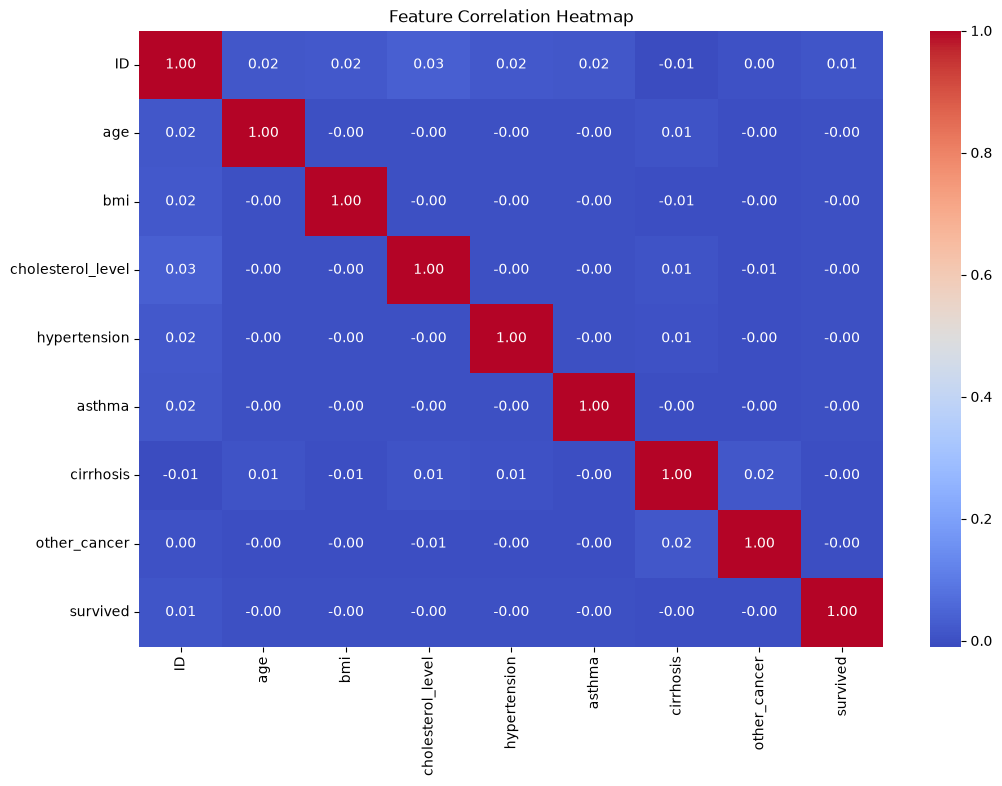

In [5]:
# Calculate correlations between numerical columns
correlation = df.select_dtypes(
    include="number"
).corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [6]:
# Display all column names
print(df.columns.tolist())

['ID', 'age', 'gender', 'country', 'diagnosis_date', 'cancer_stage', 'family_history', 'smoking_status', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer', 'treatment_type', 'end_treatment_date', 'survived']


Survival counts:
survived
0.000000e+00    26038
1.000000e+00     6511
NaN                69
6.000000e-08        4
1.000000e+05        2
Name: count, dtype: int64

Survival percentages:
survived
0.000000e+00    79.81
1.000000e+00    19.96
NaN              0.21
6.000000e-08     0.01
1.000000e+05     0.01
Name: proportion, dtype: float64


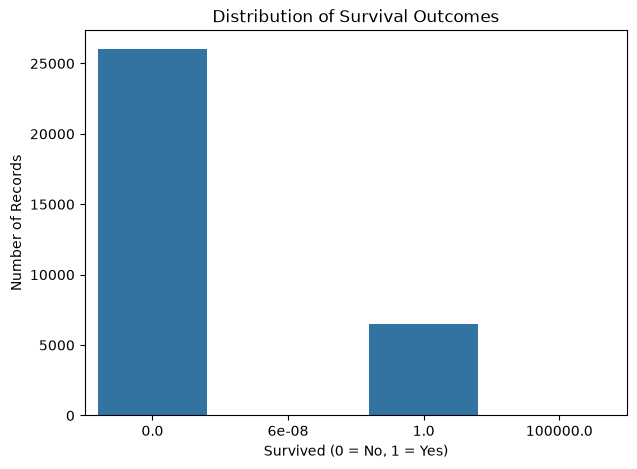

In [7]:
# Check the target variable
print("Survival counts:")
print(df["survived"].value_counts(dropna=False))

print("\nSurvival percentages:")
print(
    df["survived"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Distribution of Survival Outcomes")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

In [8]:
# Examine numerical feature ranges
columns_to_check = [
    "age",
    "bmi",
    "cholesterol_level",
    "hypertension",
    "asthma",
    "cirrhosis",
    "other_cancer"
]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print(df[col].describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    ))


--- age ---
count    3.256300e+04
mean     5.123123e+02
std      4.808908e+04
min      3.060000e-06
1%       3.200000e+01
5%       3.900000e+01
50%      5.500000e+01
95%      7.000000e+01
99%      7.700000e+01
max      5.700000e+06
Name: age, dtype: float64

--- bmi ---
count    3.257000e+04
mean     3.907300e+02
std      3.348597e+04
min      1.398000e-06
1%       1.640000e+01
5%       1.780000e+01
50%      3.060000e+01
95%      4.340000e+01
99%      4.470000e+01
max      4.100000e+06
Name: bmi, dtype: float64

--- cholesterol_level ---
count    3.254800e+04
mean     9.190069e+03
std      4.393908e+05
min      1.446000e-05
1%       1.520000e+02
5%       1.610000e+02
50%      2.420000e+02
95%      2.930000e+02
99%      2.990000e+02
max      2.770000e+07
Name: cholesterol_level, dtype: float64

--- hypertension ---
count     32570.000000
mean         16.111514
std        1238.928310
min           0.000000
1%            0.000000
5%            0.000000
50%           1.000000
95%         

In [9]:
binary_columns = [
    "hypertension",
    "asthma",
    "cirrhosis",
    "other_cancer",
    "survived"
]

for col in binary_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


hypertension:
hypertension
1.000000e+00    24752
0.000000e+00     7809
NaN                54
1.000000e+05        5
6.000000e-08        4
Name: count, dtype: int64

asthma:
asthma
0.000000e+00    17410
1.000000e+00    15132
NaN                74
6.000000e-08        5
1.000000e+05        3
Name: count, dtype: int64

cirrhosis:
cirrhosis
0.000000e+00    25716
1.000000e+00     6840
NaN                65
6.000000e-08        3
Name: count, dtype: int64

other_cancer:
other_cancer
0.0    30104
1.0     2473
NaN       47
Name: count, dtype: int64

survived:
survived
0.000000e+00    26038
1.000000e+00     6511
NaN                69
6.000000e-08        4
1.000000e+05        2
Name: count, dtype: int64


In [10]:
categorical_columns = [
    "gender",
    "country",
    "cancer_stage",
    "family_history",
    "smoking_status",
    "treatment_type"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- gender ---
gender
Male      16479
Female    16145
Name: count, dtype: int64

--- country ---
country
Ireland           1315
Malta             1305
Poland            1300
Italy             1277
France            1276
Romania           1270
Portugal          1265
Hungary           1262
Greece            1260
Estonia           1257
Netherlands       1253
Denmark           1251
Latvia            1245
Germany           1245
Luxembourg        1243
Finland           1237
Lithuania         1209
Slovakia          1199
Slovenia          1189
Czech Republic    1166
Croatia           1160
Cyprus            1156
Spain             1096
Bulgaria          1094
Belgium           1053
Sweden            1025
Austria           1016
Name: count, dtype: int64

--- cancer_stage ---
cancer_stage
Stage IV     12985
Stage I      12467
Stage II      3657
Stage III     3515
Name: count, dtype: int64

--- family_history ---
family_history
No     16354
Yes    16270
Name: count, dtype: int64

--- smoking_status

In [11]:
# Convert dates into datetime format
df["diagnosis_date"] = pd.to_datetime(
    df["diagnosis_date"],
    errors="coerce"
)

df["end_treatment_date"] = pd.to_datetime(
    df["end_treatment_date"],
    errors="coerce"
)

print("Diagnosis date range:")
print(df["diagnosis_date"].min())
print(df["diagnosis_date"].max())

print("\nTreatment end date range:")
print(df["end_treatment_date"].min())
print(df["end_treatment_date"].max())

# Check dates occurring before diagnosis
print(
    "\nTreatment ending before diagnosis:",
    (
        df["end_treatment_date"] < df["diagnosis_date"]
    ).sum()
)

Diagnosis date range:
2014-06-02 00:00:00
2024-05-30 00:00:00

Treatment end date range:
2014-12-05 00:00:00
2026-05-19 00:00:00

Treatment ending before diagnosis: 0


In [12]:
import numpy as np
import pandas as pd

# Work on a copy of the original dataset
data = df.copy()

# 1. Clean the target column
# Only 0 and 1 are valid survival labels
data["survived"] = data["survived"].where(
    data["survived"].isin([0, 1])
)

# 2. Clean binary feature columns
binary_columns = [
    "hypertension",
    "asthma",
    "cirrhosis",
    "other_cancer"
]

for col in binary_columns:
    data[col] = data[col].where(
        data[col].isin([0, 1])
    )

# 3. Handle physically implausible numerical values
# Replace invalid values with NaN so they can be imputed

data.loc[
    (data["age"] < 1) | (data["age"] > 120),
    "age"
] = np.nan

data.loc[
    (data["bmi"] < 10) | (data["bmi"] > 80),
    "bmi"
] = np.nan

data.loc[
    (data["cholesterol_level"] < 50)
    | (data["cholesterol_level"] > 1000),
    "cholesterol_level"
] = np.nan

# 4. Remove records with missing or invalid target labels
data = data.dropna(subset=["survived"]).copy()

# Convert target to integer
data["survived"] = data["survived"].astype(int)

print("Shape after cleaning:", data.shape)

print("\nTarget distribution:")
print(data["survived"].value_counts())

print("\nMissing values after cleaning:")
print(data.isnull().sum())

Shape after cleaning: (32549, 17)

Target distribution:
survived
0    26038
1     6511
Name: count, dtype: int64

Missing values after cleaning:
ID                     0
age                   68
gender                 0
country                0
diagnosis_date         0
cancer_stage           0
family_history         0
smoking_status         0
bmi                   71
cholesterol_level     93
hypertension          63
asthma                82
cirrhosis             68
other_cancer          47
treatment_type         0
end_treatment_date     0
survived               0
dtype: int64


In [13]:
# Extract diagnosis year
data["diagnosis_year"] = data["diagnosis_date"].dt.year

# Remove columns that should not be model inputs
data = data.drop(
    columns=[
        "ID",
        "diagnosis_date",
        "end_treatment_date",
        "treatment_type"
    ]
)

# Separate features and target
X = data.drop(columns=["survived"])
y = data["survived"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())


Feature shape: (32549, 13)
Target shape: (32549,)

Feature columns:
['age', 'gender', 'country', 'cancer_stage', 'family_history', 'smoking_status', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer', 'diagnosis_year']


In [14]:
from sklearn.model_selection import train_test_split

# Identify numerical and categorical features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer']

Categorical features:
['gender', 'country', 'cancer_stage', 'family_history', 'smoking_status']


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data: (26039, 13)
Testing data: (6510, 13)

Training target distribution:
survived
0    0.8
1    0.2
Name: proportion, dtype: float64

Testing target distribution:
survived
0    0.8
1    0.2
Name: proportion, dtype: float64


In [19]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

# Train and evaluate models
for name, model in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred_temp = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred_temp),
        "Precision": precision_score(
            y_test, y_pred_temp, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_temp, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred_temp, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            pipeline.predict_proba(X_test)[:, 1]
        )
    })

    trained_models[name] = pipeline

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

print("\nAll models trained successfully!")

Training Logistic Regression...


NameError: name 'preprocessor' is not defined

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessor created successfully!")
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Preprocessor created successfully!
Numerical features: ['age', 'bmi', 'cholesterol_level', 'hypertension', 'asthma', 'cirrhosis', 'other_cancer']
Categorical features: ['gender', 'country', 'cancer_stage', 'family_history', 'smoking_status']


In [21]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

# Train and evaluate models
for name, model in models.items():

    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred_temp = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred_temp),
        "Precision": precision_score(
            y_test, y_pred_temp, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_temp, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred_temp, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            pipeline.predict_proba(X_test)[:, 1]
        )
    })

    trained_models[name] = pipeline

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

print("\nAll models trained successfully!")

Training Logistic Regression...
Training Random Forest...
Training Extra Trees...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.5244,0.2078,0.4900,0.2919,0.5149
1,Random Forest,0.7719,0.2741,0.0853,0.1301,0.5405
2,Extra Trees,0.7743,0.2808,0.0822,0.1272,0.5367



All models trained successfully!


In [22]:
# Select the best model based on F1-score
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

# Predict on test data
y_pred = best_model.predict(X_test)

from sklearn.metrics import classification_report

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Survived (0)", "Survived (1)"],
        zero_division=0
    )
)

Best Model: Logistic Regression

Classification Report:
                  precision    recall  f1-score   support

Not Survived (0)       0.81      0.53      0.64      5208
    Survived (1)       0.21      0.49      0.29      1302

        accuracy                           0.52      6510
       macro avg       0.51      0.51      0.47      6510
    weighted avg       0.69      0.52      0.57      6510



In [23]:
import os
import pandas as pd

# Create output folder
os.makedirs("outputs", exist_ok=True)

# Generate predictions
prediction_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Survival_Probability": best_model.predict_proba(X_test)[:, 1]
})

# Save predictions
prediction_df.to_csv(
    "outputs/predictions.csv",
    index=False
)

print("Prediction CSV saved successfully!")

display(prediction_df.head())

Prediction CSV saved successfully!


,Actual,Predicted,Survival_Probability
0,0,1,0.522060
1,0,0,0.452828
2,0,0,0.456818
3,0,0,0.417282
4,1,0,0.496436


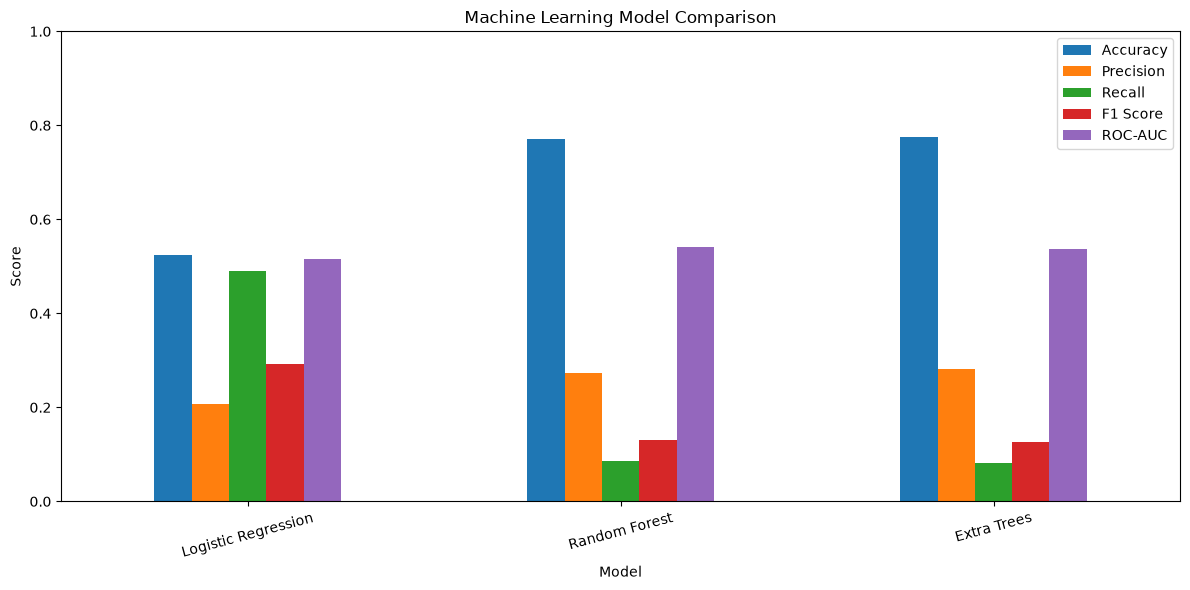

Model comparison chart saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import os

os.makedirs("outputs", exist_ok=True)

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully!")

In [ ]:
import os

for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

outputs\model_comparison.png
outputs\predictions.csv


In [ ]:
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.524424,0.207818,0.490015,0.291857,0.514870
1,Random Forest,0.771889,0.274074,0.085253,0.130053,0.540474
2,Extra Trees,0.774347,0.280840,0.082181,0.127154,0.536683
